In [15]:
from pathlib import Path
from collections import defaultdict, Counter
import csv
import pandas as pd
import matplotlib.pyplot as plt

from Bio import SeqIO
from Bio.SeqRecord import SeqRecord

## 1. Set input and output paths

In [2]:
busco_full_table = Path("/home/lehoanglinh/project/T_vietnamensis/data/2024_Tylototriton_vietnamensis_Wild_Genomes/Linh_Analysis/results/production_run/genome_qc/busco/04_hifi_asm_purged_dups_05_15_90_asm10/eukaryota_odb12/run_eukaryota_odb12/full_table.tsv")
assembly_fasta = Path("/home/lehoanglinh/project/T_vietnamensis/data/2024_Tylototriton_vietnamensis_Wild_Genomes/Linh_Analysis/assemblies/04_hifi_asm_purged_dups_05_15_90_asm10/T_vietnamensis_hifi_asm_purged_dups_05_15_90_asm10.fa")

outdir = Path("busco_duplicated_contigs")
outdir.mkdir(parents=True, exist_ok=True)

duplicated_regions_tsv = outdir / "duplicated_busco_regions.tsv"
contig_summary_tsv = outdir / "duplicated_busco_contig_summary.tsv"
busco_copy_summary_tsv = outdir / "duplicated_busco_copy_summary.tsv"
contigs_containing_duplicated_busco_fasta = outdir / "contigs_containing_duplicated_busco.fa"

## 2. Extract all BUSCO records from full_table.tsv

In [3]:
busco_df = pd.read_csv(
    busco_full_table,
    sep="\t",
    comment="#"
)

busco_df.head()

,Busco id,Status,Sequence,Gene Start,Gene End,Strand,Score,Length,OrthoDB url,Description
0,88at2759,Duplicated,ptg001356l,3348273,3401381,+,87.4,90,https://v12-1.orthodb.org/?query=88at2759,ribosomal protein
1,88at2759,Duplicated,ptg012299l,7219,3488,-,82.9,90,https://v12-1.orthodb.org/?query=88at2759,ribosomal protein
2,844at2759,Duplicated,ptg000294l,15838421,15620331,-,1201.2,699,https://v12-1.orthodb.org/?query=844at2759,DNA replication licensing factor
3,844at2759,Duplicated,ptg003749l,62466,71966,+,1195.6,699,https://v12-1.orthodb.org/?query=844at2759,DNA replication licensing factor
4,1650at2759,Duplicated,ptg011642l,32818,24246,-,286.8,206,https://v12-1.orthodb.org/?query=1650at2759,Exosome complex


## 3. Extract all Duplicated records from the dataframe
Also find out which and how many contigs contain duplicated BUSCOs

In [4]:
duplicated_buscos_df = busco_df[busco_df["Status"] == "Duplicated"].copy()
duplicated_buscos_df.head()


,Busco id,Status,Sequence,Gene Start,Gene End,Strand,Score,Length,OrthoDB url,Description
0,88at2759,Duplicated,ptg001356l,3348273,3401381,+,87.4,90,https://v12-1.orthodb.org/?query=88at2759,ribosomal protein
1,88at2759,Duplicated,ptg012299l,7219,3488,-,82.9,90,https://v12-1.orthodb.org/?query=88at2759,ribosomal protein
2,844at2759,Duplicated,ptg000294l,15838421,15620331,-,1201.2,699,https://v12-1.orthodb.org/?query=844at2759,DNA replication licensing factor
3,844at2759,Duplicated,ptg003749l,62466,71966,+,1195.6,699,https://v12-1.orthodb.org/?query=844at2759,DNA replication licensing factor
4,1650at2759,Duplicated,ptg011642l,32818,24246,-,286.8,206,https://v12-1.orthodb.org/?query=1650at2759,Exosome complex


In [5]:
contig_with_duplicated_busco_counts = (
    duplicated_buscos_df["Sequence"]
    .value_counts()
    .rename_axis("contig")
    .reset_index(name="duplicated_busco_count")
)

contig_with_duplicated_busco_counts.head()

,contig,duplicated_busco_count
0,ptg000372l,3
1,ptg009477l,3
2,ptg000557l,3
3,ptg000317l,2
4,ptg000062l,2


In [6]:
contig_with_duplicated_busco_counts["duplicated_busco_count"].sum()

np.int64(202)

In [7]:
contigs_containing_duplicated_busco_set = set(
    contig_with_duplicated_busco_counts["contig"]
    .dropna()
    .astype(str)
)

print(f"Number of contigs containing Duplicated BUSCOs: {len(contigs_containing_duplicated_busco_set):,}")

Number of contigs containing Duplicated BUSCOs: 191


In [9]:
found_contigs = set()
records_written = 0

with open(contigs_containing_duplicated_busco_fasta, "w") as out_handle:
    for record in SeqIO.parse(assembly_fasta, "fasta"):
        if record.id in contigs_containing_duplicated_busco_set:
            SeqIO.write(record, out_handle, "fasta")
            found_contigs.add(record.id)
            records_written += 1

print(f"Contigs requested: {len(contigs_containing_duplicated_busco_set):,}")
print(f"Contigs found in FASTA: {len(found_contigs):,}")
print(f"Contigs written: {records_written:,}")
print(f"Output FASTA: {contigs_containing_duplicated_busco_fasta}")

Contigs requested: 191
Contigs found in FASTA: 191
Contigs written: 191
Output FASTA: busco_duplicated_contigs/contigs_containing_duplicated_busco.fa


## 4. Load mosdepth per-contig coverage summary
Mosdepth's `*.mosdepth.summary.txt` file has one row per contig (plus a final `total` row) with columns:
`chrom  length  bases  mean  min  max`. We load it, split off the genome-wide `total` row, and keep the per-contig table for merging with the BUSCO duplication results.

In [10]:
mosdepth_summary = Path(
    "/home/lehoanglinh/project/T_vietnamensis/data/2024_Tylototriton_vietnamensis_Wild_Genomes/Linh_Analysis/results/production_run/genome_qc/mosdepth/04_hifi_asm_purged_dups_05_15_90_asm10/04_hifi_asm_purged_dups_05_15_90_asm10.hifi.mosdepth.summary.txt"
)  # <-- update to your actual mosdepth summary path

coverage_df = pd.read_csv(mosdepth_summary, sep="\t")

# The last row is the genome-wide "total" row, not a real contig -- pull it out separately
genome_total_row = coverage_df[coverage_df["chrom"] == "total"].iloc[0]
genome_mean_coverage = genome_total_row["mean"]

coverage_df = coverage_df[coverage_df["chrom"] != "total"].copy()
coverage_df = coverage_df.rename(columns={"chrom": "contig"})

print(f"Genome-wide mean coverage (mosdepth total row): {genome_mean_coverage:.2f}x")
print(f"Number of contigs in mosdepth summary: {len(coverage_df):,}")
coverage_df.head()

Genome-wide mean coverage (mosdepth total row): 22.18x
Number of contigs in mosdepth summary: 12,552


,contig,length,bases,mean,min,max
0,ptg000001l,5594703,123488683,22.07,2,70
1,ptg000002l,17454235,382549996,21.92,0,125
2,ptg000003l,2095740,31214526,14.89,0,45
3,ptg000004l,119968120,2704994764,22.55,0,215
4,ptg000005l,35333353,760145572,21.51,0,186


## 5. Merge coverage with the duplicated-BUSCO contig list
Join the per-contig mosdepth coverage onto `contig_with_duplicated_busco_counts` (built in section 3) so each duplicated-BUSCO-containing contig has its length, mean/min/max coverage, and how many duplicated BUSCOs it carries.

In [11]:
duplicated_contig_coverage = contig_with_duplicated_busco_counts.merge(
    coverage_df[["contig", "length", "mean", "min", "max"]],
    on="contig",
    how="left",
)

duplicated_contig_coverage = duplicated_contig_coverage.rename(columns={"mean": "mean_coverage"})

# Coverage relative to the genome-wide average -- values well above ~1x can indicate
# a collapsed/uncollapsed duplicate region rather than a true single-copy contig
duplicated_contig_coverage["coverage_vs_genome_mean"] = (
    duplicated_contig_coverage["mean_coverage"] / genome_mean_coverage
)

duplicated_contig_coverage = duplicated_contig_coverage.sort_values(
    "mean_coverage", ascending=False
).reset_index(drop=True)

missing_coverage = duplicated_contig_coverage["mean_coverage"].isna().sum()
if missing_coverage:
    print(f"Warning: {missing_coverage} duplicated-BUSCO contigs have no matching entry in the mosdepth summary")

duplicated_contig_coverage.head(20)

,contig,duplicated_busco_count,length,mean_coverage,min,max,coverage_vs_genome_mean
0,ptg013808l,1,165220,71.88,1,401,3.240757
1,ptg000577l,1,5690835,51.77,2,542,2.334085
2,ptg004431l,1,12534912,34.17,0,796,1.540577
3,ptg004698l,1,972454,34.16,0,485,1.540126
4,ptg002173l,1,10384578,26.60,0,1622,1.199279
5,ptg000686l,1,4621305,25.65,1,89,1.156447
6,ptg000134l,1,23133997,24.58,0,101,1.108206
7,ptg000205l,1,16497404,24.23,0,122,1.092426
8,ptg000209l,1,16587211,24.20,0,78,1.091073
9,ptg000311l,1,8379164,24.19,1,71,1.090622


## 6. Summary statistics: duplicated-BUSCO contigs vs. all contigs
Compare the coverage distribution of contigs that carry duplicated BUSCOs against the genome-wide distribution. Contigs sitting near ~2x (or higher multiples) of the genome mean are classic signatures of uncollapsed haplotigs/duplicated regions that `purge_dups` should target.

In [12]:
print("Coverage stats -- contigs WITH duplicated BUSCOs:")
display(duplicated_contig_coverage["mean_coverage"].describe())

print("\nCoverage stats -- ALL contigs in the assembly:")
display(coverage_df["mean"].describe())

print(f"\nGenome-wide mean coverage: {genome_mean_coverage:.2f}x")
print(
    "Median coverage of duplicated-BUSCO contigs: "
    f"{duplicated_contig_coverage['mean_coverage'].median():.2f}x "
    f"({duplicated_contig_coverage['coverage_vs_genome_mean'].median():.2f}x genome mean)"
)

Coverage stats -- contigs WITH duplicated BUSCOs:


count    191.000000
mean      14.698743
std       10.120036
min        2.880000
25%        5.690000
50%        9.400000
75%       22.855000
max       71.880000
Name: mean_coverage, dtype: float64


Coverage stats -- ALL contigs in the assembly:


count    12552.000000
mean        10.289259
std         23.884052
min          1.530000
25%          4.960000
50%          5.920000
75%          9.455000
max        989.990000
Name: mean, dtype: float64


Genome-wide mean coverage: 22.18x
Median coverage of duplicated-BUSCO contigs: 9.40x (0.42x genome mean)


In [13]:
# Flag contigs whose coverage looks like a collapsed 2-copy (or higher) region
# Adjust the threshold to whatever multiple makes sense for your data (1.5x, 1.8x, 2x, etc.)
HIGH_COVERAGE_THRESHOLD = 1.5

likely_uncollapsed = duplicated_contig_coverage[
    duplicated_contig_coverage["coverage_vs_genome_mean"] >= HIGH_COVERAGE_THRESHOLD
].copy()

print(
    f"Duplicated-BUSCO contigs with coverage >= {HIGH_COVERAGE_THRESHOLD}x genome mean: "
    f"{len(likely_uncollapsed):,} / {len(duplicated_contig_coverage):,}"
)
likely_uncollapsed.head(20)

Duplicated-BUSCO contigs with coverage >= 1.5x genome mean: 4 / 191


,contig,duplicated_busco_count,length,mean_coverage,min,max,coverage_vs_genome_mean
0,ptg013808l,1,165220,71.88,1,401,3.240757
1,ptg000577l,1,5690835,51.77,2,542,2.334085
2,ptg004431l,1,12534912,34.17,0,796,1.540577
3,ptg004698l,1,972454,34.16,0,485,1.540126


## 7. Plot coverage distribution
Histogram comparing the mean-coverage distribution of all contigs vs. the duplicated-BUSCO contigs, with the genome-wide mean marked for reference.

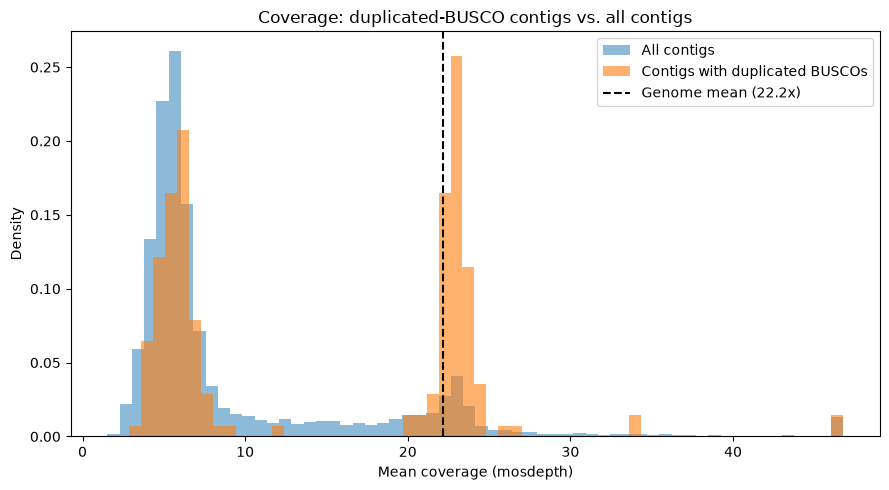

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))

bins = 60
coverage_cap = coverage_df["mean"].quantile(0.99)  # trim extreme outliers for a readable plot

ax.hist(
    coverage_df["mean"].clip(upper=coverage_cap),
    bins=bins,
    alpha=0.5,
    label="All contigs",
    density=True,
)
ax.hist(
    duplicated_contig_coverage["mean_coverage"].clip(upper=coverage_cap),
    bins=bins,
    alpha=0.6,
    label="Contigs with duplicated BUSCOs",
    density=True,
)
ax.axvline(genome_mean_coverage, color="black", linestyle="--", label=f"Genome mean ({genome_mean_coverage:.1f}x)")

ax.set_xlabel("Mean coverage (mosdepth)")
ax.set_ylabel("Density")
ax.set_title("Coverage: duplicated-BUSCO contigs vs. all contigs")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Save results

In [ ]:
duplicated_contig_coverage.to_csv(contig_summary_tsv, sep="\t", index=False)
print(f"Saved duplicated-BUSCO-contig coverage summary to: {contig_summary_tsv}")

## 9. Number of copies per BUSCO

In [17]:
dup_df = busco_df[busco_df["Status"] == "Duplicated"].copy()
# Count how many copies each Busco id has
copy_counts = (
    dup_df.groupby("Busco id")
    .size()
    .rename("n_copies")
    .reset_index()
    .sort_values("n_copies", ascending=False)
)

# Distribution: how many BUSCOs have exactly 2 copies, 3 copies, 4 copies, etc.
distribution = copy_counts["n_copies"].value_counts().sort_index()

n_total_duplicated_genes = copy_counts.shape[0]
n_exactly_two = (copy_counts["n_copies"] == 2).sum()
pct_exactly_two = 100 * n_exactly_two / n_total_duplicated_genes

print(f"Total 'Duplicated' BUSCO genes (unique): {n_total_duplicated_genes}")
print(f"Genes with EXACTLY 2 copies: {n_exactly_two} ({pct_exactly_two:.1f}%)")
print("\nDistribution of copy count per gene:")
print(distribution.to_string())

print("\nGenes with >2 copies (if any) -- more likely true gene family/paralogs rather than allelic haplotigs:")
more_than_two = copy_counts[copy_counts["n_copies"] > 2]
print(more_than_two.to_string(index=False) if not more_than_two.empty else "(none)")

Total 'Duplicated' BUSCO genes (unique): 100
Genes with EXACTLY 2 copies: 98 (98.0%)

Distribution of copy count per gene:
n_copies
2    98
3     2

Genes with >2 copies (if any) -- more likely true gene family/paralogs rather than allelic haplotigs:
    Busco id  n_copies
 30343at2759         3
189968at2759         3


Status values found in full_table.tsv: <StringArray>
['Duplicated', 'Complete', 'Fragmented']
Length: 3, dtype: str

Total contigs: 12,552
Total assembly length: 25,185,052,729 bp
The top 20% longest contigs (2,510 contigs) contain 97.34% of total assembly length

Contigs with Duplicated BUSCOs: 191
  -> in TOP 20% longest contigs:      114 (59.7%)
  -> in BOTTOM 80% (shorter) contigs:  77 (40.3%)

Contigs with Single-copy BUSCOs: 24
  -> in TOP 20% longest contigs:      22 (91.7%)
  -> in BOTTOM 80% (shorter) contigs:  2 (8.3%)


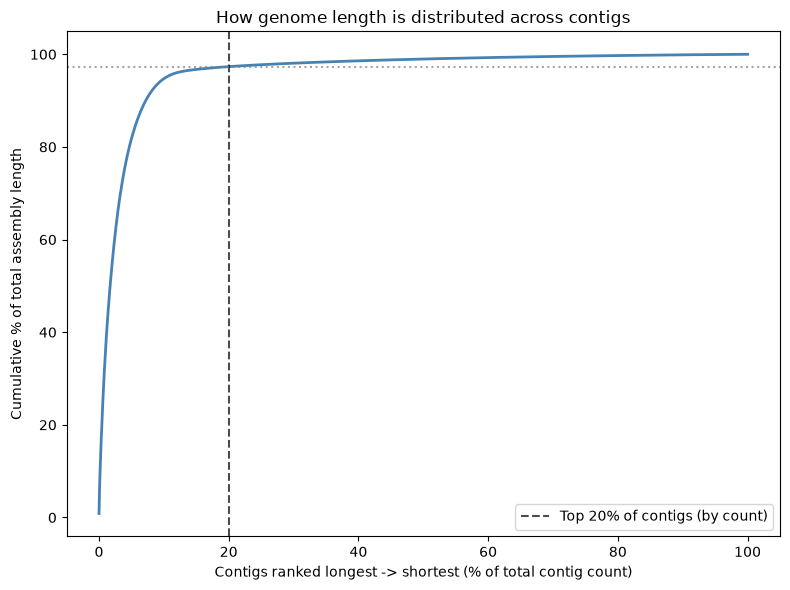


Saved plot: contig_length_skew.png


In [18]:
# --- Load per-contig lengths from mosdepth ---
coverage_df = pd.read_csv(mosdepth_summary, sep="\t")
coverage_df = coverage_df[coverage_df["chrom"] != "total"].copy()
coverage_df = coverage_df.rename(columns={"chrom": "contig"})

# --- Load BUSCO table, split into Duplicated vs Single-copy contig sets ---
busco_df = pd.read_csv(busco_full_table, sep="\t", comment="#")
dup_contigs = set(busco_df.loc[busco_df["Status"] == "Duplicated", "Sequence"].dropna())
single_contigs = set(busco_df.loc[busco_df["Status"] == "Complete", "Sequence"].dropna()) - dup_contigs
# Note: some BUSCO tables label single-copy rows as "Complete" (not "Single_copy") --
# if yours uses a different label, check busco_df["Status"].unique() and adjust above.

print("Status values found in full_table.tsv:", busco_df["Status"].unique())

# --- Build cumulative-length curve (contigs ranked longest -> shortest) ---
sorted_df = coverage_df.sort_values("length", ascending=False).reset_index(drop=True)
sorted_df["cum_length"] = sorted_df["length"].cumsum()
total_length = sorted_df["length"].sum()
sorted_df["cum_pct_length"] = 100 * sorted_df["cum_length"] / total_length
sorted_df["contig_rank_pct"] = 100 * (sorted_df.index + 1) / len(sorted_df)

# Find where the top 20% of contigs (by count) sit on the length curve
top20_cutoff_idx = int(len(sorted_df) * 0.20)
pct_length_in_top20 = sorted_df.loc[top20_cutoff_idx - 1, "cum_pct_length"]
print(f"\nTotal contigs: {len(sorted_df):,}")
print(f"Total assembly length: {total_length:,} bp")
print(f"The top 20% longest contigs ({top20_cutoff_idx:,} contigs) contain "
      f"{pct_length_in_top20:.2f}% of total assembly length")

# --- Mark which contigs are in the "top 20% by length" group ---
sorted_df["in_top20_by_length"] = sorted_df.index < top20_cutoff_idx
top20_contig_set = set(sorted_df.loc[sorted_df["in_top20_by_length"], "contig"])

# --- Check where duplicated-BUSCO contigs fall relative to top20 ---
dup_in_top20 = dup_contigs & top20_contig_set
dup_outside_top20 = dup_contigs - top20_contig_set

print(f"\nContigs with Duplicated BUSCOs: {len(dup_contigs)}")
print(f"  -> in TOP 20% longest contigs:      {len(dup_in_top20)} "
      f"({100*len(dup_in_top20)/len(dup_contigs):.1f}%)")
print(f"  -> in BOTTOM 80% (shorter) contigs:  {len(dup_outside_top20)} "
      f"({100*len(dup_outside_top20)/len(dup_contigs):.1f}%)")

# --- Same check for single-copy BUSCO contigs, for comparison ---
if single_contigs:
    single_in_top20 = single_contigs & top20_contig_set
    single_outside_top20 = single_contigs - top20_contig_set
    print(f"\nContigs with Single-copy BUSCOs: {len(single_contigs)}")
    print(f"  -> in TOP 20% longest contigs:      {len(single_in_top20)} "
          f"({100*len(single_in_top20)/len(single_contigs):.1f}%)")
    print(f"  -> in BOTTOM 80% (shorter) contigs:  {len(single_outside_top20)} "
          f"({100*len(single_outside_top20)/len(single_contigs):.1f}%)")

# --- Plot the Lorenz-style cumulative length curve ---
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(sorted_df["contig_rank_pct"], sorted_df["cum_pct_length"], color="steelblue", lw=2)
ax.axvline(20, color="black", linestyle="--", alpha=0.7, label="Top 20% of contigs (by count)")
ax.axhline(pct_length_in_top20, color="gray", linestyle=":", alpha=0.7)
ax.set_xlabel("Contigs ranked longest -> shortest (% of total contig count)")
ax.set_ylabel("Cumulative % of total assembly length")
ax.set_title("How genome length is distributed across contigs")
ax.legend()
plt.tight_layout()
plt.savefig("contig_length_skew.png", dpi=150)
plt.show()

print("\nSaved plot: contig_length_skew.png")